# Fashion-MNIST Image Classification

## Project Overview
This project explores image classification using Machine Learning
and Deep Learning models.

## Objectives
- Validate and explore the dataset.
- Analyze clothing image patterns.
- Compare Logistic Regression and CNN.
- Evaluate and improve model performance.


In [1]:

# Step 1: Import libraries and load Fashion-MNIST

import numpy as np #العمليات الحسابية على المصفوفات
import pandas as pd #تنظيم البيانات وتحليلها
import matplotlib.pyplot as plt #رسم الصور والرسوم البيانية

from tensorflow.keras.datasets import fashion_mnist

# Load the dataset
#X_train الصور التي سنستخدمها لتدريب النماذج
#y_train التصنيف الصحيح لكل صورة تدريب
#X_test and y_test  بيانات الاختبار لتقييم النماذج لاحقًا.
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data() #تحميل صور الملابس والتصنيفات



#البيانات تتكون من 70,000 صورة رمادية
#منها 60,000 للتدريب و10,000 للاختبار.

# Define the clothing classes
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Dataset loaded successfully!")
print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)
print("Image pixel range:", X_train.min(), "to", X_train.max())
print("Number of classes:", len(class_names))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)
Image pixel range: 0 to 255
Number of classes: 10


In [2]:

# Step 2: Validate the dataset

# 1. Check for missing values
print("Missing values in training images:", np.isnan(X_train).sum())
print("Missing values in testing images:", np.isnan(X_test).sum())

# 2. Check label ranges
print("Training labels range:", y_train.min(), "to", y_train.max())
print("Testing labels range:", y_test.min(), "to", y_test.max())

# 3. Check image dimensions
print("Training image dimensions:", X_train.shape[1:])
print("Testing image dimensions:", X_test.shape[1:])

# 4. Check for completely empty images
empty_train = np.sum(np.all(X_train == 0, axis=(1, 2)))
empty_test = np.sum(np.all(X_test == 0, axis=(1, 2)))

print("Completely empty training images:", empty_train)
print("Completely empty testing images:", empty_test)

# 5. Check class distribution
print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())


Missing values in training images: 0
Missing values in testing images: 0
Training labels range: 0 to 9
Testing labels range: 0 to 9
Training image dimensions: (28, 28)
Testing image dimensions: (28, 28)
Completely empty training images: 0
Completely empty testing images: 0

Training class distribution:
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


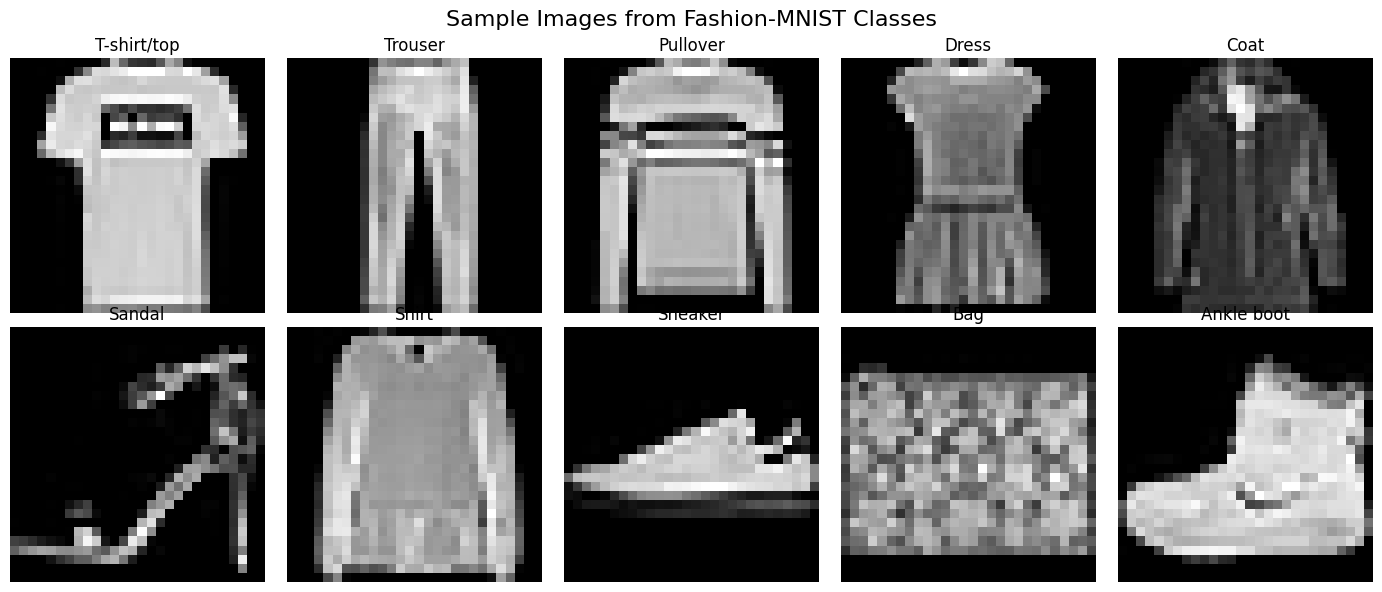

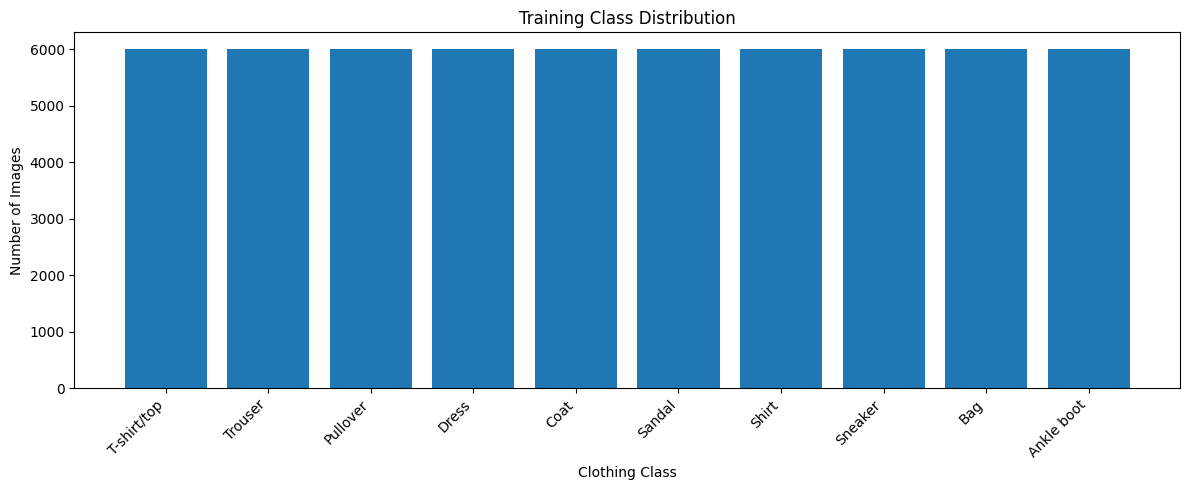

Minimum pixel intensity: 0
Maximum pixel intensity: 255
Mean pixel intensity: 72.94
Standard deviation: 90.02


In [3]:

# Step 3: Exploratory Data Analysis (EDA)

# 1. Display sample images from all 10 classes
plt.figure(figsize=(14, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Get the first training image belonging to each class
    image_index = np.where(y_train == i)[0][0]

    plt.imshow(X_train[image_index], cmap="gray")
    plt.title(class_names[i])
    plt.axis("off")

plt.suptitle("Sample Images from Fashion-MNIST Classes", fontsize=16)
plt.tight_layout()
plt.show()


# 2. Visualize training class distribution
class_counts = pd.Series(y_train).value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.bar(class_names, class_counts.values)
plt.title("Training Class Distribution")
plt.xlabel("Clothing Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 3. Display basic pixel intensity statistics
print("Minimum pixel intensity:", X_train.min())
print("Maximum pixel intensity:", X_train.max())
print("Mean pixel intensity:", round(X_train.mean(), 2))
print("Standard deviation:", round(X_train.std(), 2))


In [4]:

# Step 4: Data preprocessing

# Normalize pixel values from 0-255 to 0-1
X_train_normalized = X_train.astype("float32") / 255.0
X_test_normalized = X_test.astype("float32") / 255.0

# Flatten images for Logistic Regression
X_train_flat = X_train_normalized.reshape(len(X_train), -1)
X_test_flat = X_test_normalized.reshape(len(X_test), -1)

# Add a channel dimension for CNN
X_train_cnn = X_train_normalized[..., np.newaxis]
X_test_cnn = X_test_normalized[..., np.newaxis]

print("Logistic Regression training shape:", X_train_flat.shape)
print("Logistic Regression testing shape:", X_test_flat.shape)
print("CNN training shape:", X_train_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)
print("Normalized pixel range:",
      X_train_normalized.min(), "to", X_train_normalized.max())


Logistic Regression training shape: (60000, 784)
Logistic Regression testing shape: (10000, 784)
CNN training shape: (60000, 28, 28, 1)
CNN testing shape: (10000, 28, 28, 1)
Normalized pixel range: 0.0 to 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Results
----------------------------------------
Test Accuracy: 0.8431 (84.31%)
Training Time: 88.73 seconds

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     0.7955    0.8050    0.8002      1000
     Trouser     0.9726    0.9570    0.9647      1000
    Pullover     0.7245    0.7390    0.7317      1000
       Dress     0.8284    0.8590    0.8434      1000
        Coat     0.7395    0.7550    0.7472      1000
      Sandal     0.9459    0.9260    0.9358      1000
       Shirt     0.6247    0.5710    0.5967      1000
     Sneaker     0.9089    0.9380    0.9232      1000
         Bag     0.9333    0.9380    0.9357      1000
  Ankle boot     0.9468    0.9430    0.9449      1000

    accuracy                         0.8431     10000
   macro avg     0.8420    0.8431    0.8423     10000
weighted avg     0.8420    0.8431    0.8423     10000



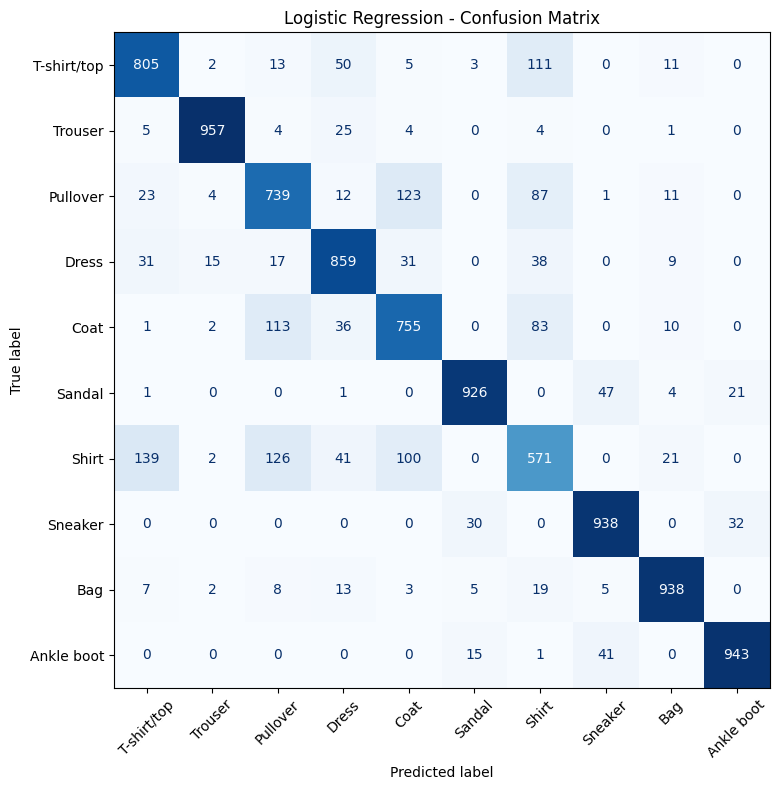

In [5]:

# Step 5: Train and evaluate Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time

# Create the model
log_reg = LogisticRegression(
    max_iter=300,
    random_state=42
)

# Train the model
start_time = time.time()

log_reg.fit(X_train_flat, y_train)

training_time = time.time() - start_time

# Predict test labels
y_pred_lr = log_reg.predict(X_test_flat)

# Evaluate the model
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Results")
print("-" * 40)
print(f"Test Accuracy: {accuracy_lr:.4f} ({accuracy_lr * 100:.2f}%)")
print(f"Training Time: {training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=class_names,
    digits=4
))

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [6]:

# Step 6: Build and train a CNN model

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import time

# Build the CNN architecture
cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

# Configure the model
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture
cnn_model.summary()

# Stop training if validation performance stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the model
start_time = time.time()

history = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

cnn_training_time = time.time() - start_time

print(f"\nCNN Training Time: {cnn_training_time:.2f} seconds")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 31s 69ms/step - accuracy: 0.7700 - loss: 0.6414 - val_accuracy: 0.8433 - val_loss: 0.4232
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 66ms/step - accuracy: 0.8534 - loss: 0.4087 - val_accuracy: 0.8693 - val_loss: 0.3467
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 67ms/step - accuracy: 0.8718 - loss: 0.3523 - val_accuracy: 0.8800 - val_loss: 0.3213
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.8840 - loss: 0.3194 - val_accuracy: 0.8920 - val_loss: 0.2927
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 28s 67ms/step - accuracy: 0.8946 - loss: 0.2938 - val_accuracy: 0.8907 - val_loss: 0.2910
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 66ms/step - accuracy: 0.9002 - loss: 0.2750 - val_accuracy: 0.8963 - val_loss: 0.2770
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step - accuracy: 0.9035 - loss: 0.2640 - val_accuracy: 0.9022 - val_loss: 0.2673
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 65ms/step - accuracy: 0.9089 - loss: 0.2464 - 

In [7]:

# Step 7: Evaluate the CNN model

from sklearn.metrics import accuracy_score, classification_report

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

y_pred_cnn = cnn_model.predict(X_test_cnn, verbose=0).argmax(axis=1)

print("CNN Evaluation Results")
print("-" * 40)
print(f"Test Accuracy: {cnn_test_accuracy * 100:.2f}%")
print(f"Test Loss: {cnn_test_loss:.4f}")
print(f"Training Time: {cnn_training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cnn,
    target_names=class_names,
    digits=4
))


CNN Evaluation Results
----------------------------------------
Test Accuracy: 90.73%
Test Loss: 0.2522
Training Time: 359.16 seconds

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     0.8304    0.8860    0.8573      1000
     Trouser     0.9909    0.9770    0.9839      1000
    Pullover     0.8601    0.8610    0.8606      1000
       Dress     0.9092    0.9210    0.9151      1000
        Coat     0.8461    0.8630    0.8545      1000
      Sandal     0.9742    0.9830    0.9786      1000
       Shirt     0.7648    0.6730    0.7160      1000
     Sneaker     0.9554    0.9640    0.9597      1000
         Bag     0.9571    0.9820    0.9694      1000
  Ankle boot     0.9737    0.9630    0.9683      1000

    accuracy                         0.9073     10000
   macro avg     0.9062    0.9073    0.9063     10000
weighted avg     0.9062    0.9073    0.9063     10000



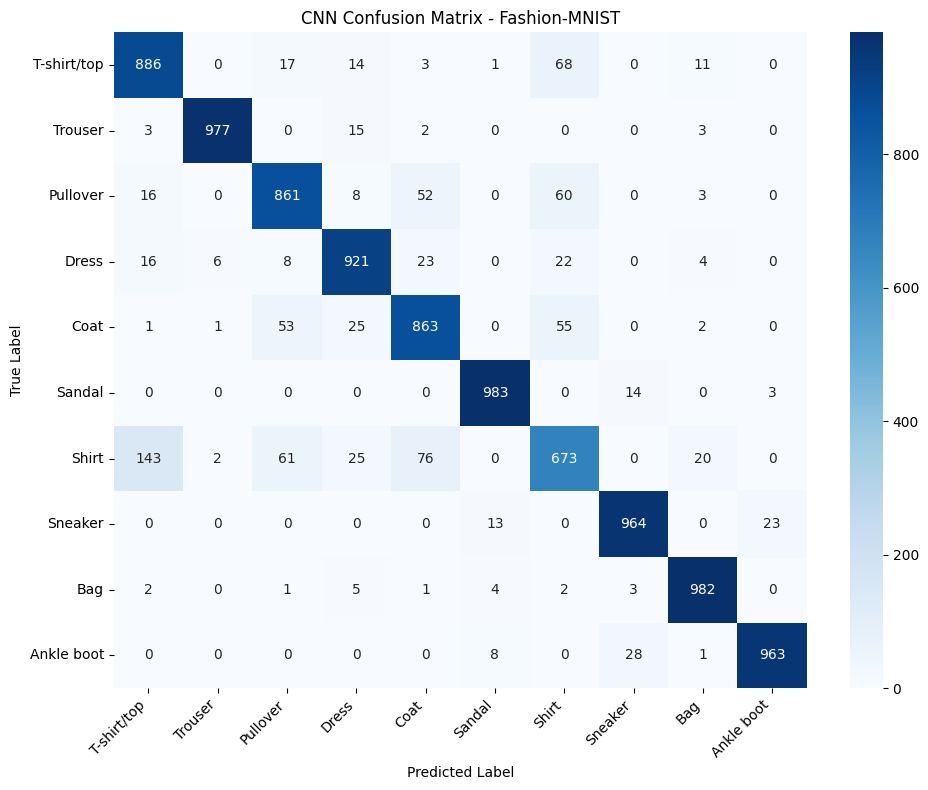

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

# Visualize the results
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_cnn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix - Fashion-MNIST")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


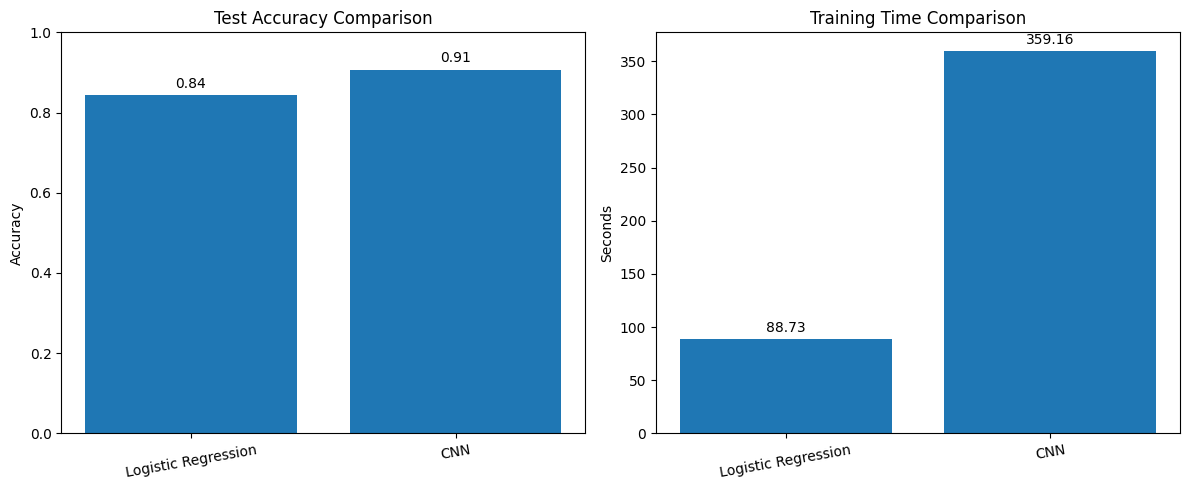

In [9]:

import matplotlib.pyplot as plt
import numpy as np

models_names = ["Logistic Regression", "CNN"]
accuracies = [0.8431, cnn_test_accuracy]
training_times = [88.73, cnn_training_time]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare test accuracy
bars = axes[0].bar(models_names, accuracies)
axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].bar_label(bars, fmt="%.2f", padding=3)
axes[0].tick_params(axis="x", rotation=10)

# Compare training time
bars = axes[1].bar(models_names, training_times)
axes[1].set_title("Training Time Comparison")
axes[1].set_ylabel("Seconds")
axes[1].bar_label(bars, fmt="%.2f", padding=3)
axes[1].tick_params(axis="x", rotation=10)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


In [10]:

import os
import json
import pandas as pd

# Create a folder for project outputs
os.makedirs("fashion_mnist_outputs", exist_ok=True)

# Save the trained CNN model
cnn_model.save("fashion_mnist_outputs/fashion_mnist_cnn.keras")

# Save model comparison results
results = pd.DataFrame({
    "Model": ["Logistic Regression", "CNN"],
    "Test Accuracy": [0.8431, float(cnn_test_accuracy)],
    "Training Time (seconds)": [
        88.73,
        float(cnn_training_time)
    ]
})

results.to_csv(
    "fashion_mnist_outputs/model_comparison.csv",
    index=False
)

# Save the class names
with open(
    "fashion_mnist_outputs/class_names.json",
    "w"
) as file:
    json.dump(
        [str(name) for name in class_names],
        file,
        indent=4
    )

print("Saved files:")
print("- fashion_mnist_cnn.keras")
print("- model_comparison.csv")
print("- class_names.json")


Saved files:
- fashion_mnist_cnn.keras
- model_comparison.csv
- class_names.json


In [11]:

import shutil
from google.colab import files

# Package all saved outputs into one ZIP file
shutil.make_archive(
    "fashion_mnist_outputs",
    "zip",
    "fashion_mnist_outputs"
)

# Download the ZIP file to your computer
files.download("fashion_mnist_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>